# Lab 11: Predicting the Premier League

## By: Hannah Sweazey, Tejas Reddy, and Hannah Dykens

In [2]:
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df = pd.read_parquet('./data/premier.parquet')
df.head(10)

,date,offense,defense,home_away,goals
0,2015-08-08,Bournemouth,Aston Villa,Home,0
1,2015-08-08,Aston Villa,Bournemouth,Away,1
2,2015-08-08,Chelsea,Swansea,Home,2
3,2015-08-08,Swansea,Chelsea,Away,2
4,2015-08-08,Everton,Watford,Home,2
5,2015-08-08,Watford,Everton,Away,2
6,2015-08-08,Leicester,Sunderland,Home,4
7,2015-08-08,Sunderland,Leicester,Away,2
8,2015-08-08,Man United,Tottenham,Home,1
9,2015-08-08,Tottenham,Man United,Away,0


[Text(0.5, 1.0, 'Do you see where this is going?'),
 Text(0.5, 0, 'Goals'),
 Text(0, 0.5, 'Frequency')]

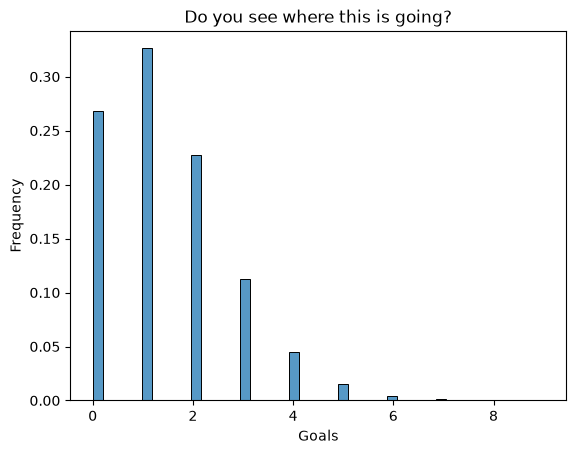

In [3]:
sns.histplot(df['goals'],
             stat='proportion').set(title='Do you see where this is going?', 
                                    xlabel='Goals', 
                                    ylabel='Frequency')

People legally bet about $20 billion annually on the English Premier League (EPL), but worldwide estimates approach $1 billion per match on average. This is an astronomical sum of money. Perhaps we can data science it.

The EPL has 20 football teams play a total of 380 matches from August to May. It is Double Round-Robin Format: Every team plays each other team twice (home and away). The outcome of each match contributes to a team's point total:

- Win: 3 points
- Draw: 1 point
- Lose: 0 points

At the end of the season, the team with the most points wins the Premier League; if a tie, the winner is the one with the bigger difference between goals scored and goals conceded (if you need further tie-breaking in what follows, decide the winner at random). If you are one of the worst three teams (18th, 19th, 20th), you get kicked out of the Premier League and demoted to EFL Championship.

Your objective for this lab is: Predict which teams win the 2026-2027 Premier League, and which get relegated. 

## 1. Fitting a Poisson

Here is the recommended specification for this exercise:

$$
\text{Goals}_{ij} \sim \text{Poisson}(\lambda_{ij}), \quad 
\lambda_{ij} = \exp \left\lbrace \beta_i \times \text{ Offense is $i$ } + \gamma_j \times \text{ Defense is $j$} + \eta \times \text{ Offense $i$ is Home } \right\rbrace
$$

There are two problems. First, Coventry has no training data: It has not been in the EPL in over 10 years, and you have to incorporate it somehow. Second, even though we dropped the constant, we have to drop one more offense or defense dummy in order for the model to be identified and avoid perfect multicolinearity. You have to decide how to solve these problems to move forwards. Make sure you understand the consequences of your choice for the subsequent analysis.

1. One-hot encode the Offense and Defense variables, handling the multicolinearity issue. Encode Home as 1 if the offense team is playing at home, and 0 otherwise. Concatenate these into a design matrix, $X$, without adding a constant. State which coefficient you fixed or category you omitted, explain how that affects coefficient interpretation, and distinguish parameters estimated from historical data from assumptions supplied for Coventry.
2. Run Poisson regression of `goals` on $X$. 

Answer the following questions:

1. Using the `./data/premier.parquet` data, fit the proposed model for the 2015-2016 through 2025-2026 seasons. 
2. What does $\beta_i$ represent for each team $i$? What does $\gamma_j$ represent for each team $j$? What does $\eta$ represent? Explain these intuitively (in terms of winning and losing) and mathematically (in terms of the predictions).
3. Make a scatterplot of $\beta_i$ against $\gamma_i$. Are there any patterns you notice? 
4. Can you easily rank the teams from best to worst from this plot? Explain why or why not. 
5. If you like, you can adopt a more complex specification for your regression, or stick with this one. Either way, provide two or three suggestions about how you could use the available data to improve the model, or other data you'd like to add to the analysis to improve it.

## 2. Simulate a Single Match

1. Given your fitted model, you can now easily simulate a match. Write a function `simulate_match(home,away,N)` that returns $N$ pairs of randomly drawn sets of goals for the `home` and `away` teams. (Hint: You will probably want to use `lam = your_model.predict(new_match)` and `np.random.poisson(lam, size=( N , len(lam) ) )`).
2. Write a second function that takes the $N \times 2 $ vector of realized goals, and converts it into a 3-tuple, giving the probability the home team wins, the match is a draw, and the away team wins.

## 3. Simulate the 2026-2027 Season

In the `./data` directory, there is a file `premier_league_2026_27.csv`.

1. Simulate the first (filled-in) third of the season. How well do your predictions align with the actual outcomes? Which outcomes did you find most surprising, relative to your predictions?
2. Simulate the second (blank) two-thirds of the season, taking the first third of the season as given. Who do you predict will win (top 4 teams)? Who do you predict will be relegated (bottom 3 teams)?
3. Simulate the entire season. Who do you predict will win (top 4 teams)? Who do you predict will be relegated (bottom 3 teams)?
4. How do your answers change from part 2 to part 3? How valuable is the existing information from the part of the season that's already been decided?

To get good estimates of these outcomes, you should estimate the season about 2500 to 5000 times, to ensure that your results aren't vulnerable to sampling variation at the level of the simulation.

## 4. Explain Your Results

Write a short explanation of your analyis and predictions:

1. < One paragraph on methodology, explaining why the Poisson PMF is a good fit for this application over linear or log-linear regression.
2. < One paragraph and a plot describing your offensive/defensive rankings and the home-field-effect.
3. < One paragraph and a table describing which teams you think will win the Premier League, and which are most likely to be relegated.
4. < One paragraph explaining how much your predictions changes from the beginning of the season to now. Which teams are underperforming or overperforming?

The whole summary should be less than 2 pages of text (plots may push it over this limit and that is okay). Write as succinctly as possible. I am not interested in what AI says about your lab. 